In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/adityaraiiiii/plumbing-demand-dataset/README.md
/kaggle/input/datasets/adityaraiiiii/plumbing-demand-dataset/branches.csv
/kaggle/input/datasets/adityaraiiiii/plumbing-demand-dataset/calendar.csv
/kaggle/input/datasets/adityaraiiiii/plumbing-demand-dataset/daily_demand.csv
/kaggle/input/datasets/adityaraiiiii/plumbing-demand-dataset/generate_plumbing_data.py
/kaggle/input/datasets/adityaraiiiii/plumbing-demand-dataset/jobs.csv
/kaggle/input/datasets/adityaraiiiii/plumbing-demand-dataset/marketing_daily.csv
/kaggle/input/datasets/adityaraiiiii/plumbing-demand-dataset/weather_daily.csv


In [2]:
import os, glob
import pandas as pd

def find_base():
    hits = glob.glob("/kaggle/input/**/daily_demand.csv", recursive=True)
    if hits:
        return os.path.dirname(hits[0])
    import kagglehub  
    p = kagglehub.dataset_download("adityaraiiiii/plumbing-demand-dataset")
    hits = glob.glob(os.path.join(p, "**", "daily_demand.csv"), recursive=True)
    return os.path.dirname(hits[0])

BASE = find_base()
print("Reading from:", BASE)

demand    = pd.read_csv(f"{BASE}/daily_demand.csv",    parse_dates=["date"])
weather   = pd.read_csv(f"{BASE}/weather_daily.csv",   parse_dates=["date"])
marketing = pd.read_csv(f"{BASE}/marketing_daily.csv", parse_dates=["date"])
calendar  = pd.read_csv(f"{BASE}/calendar.csv",        parse_dates=["date"])
branches  = pd.read_csv(f"{BASE}/branches.csv",        parse_dates=["open_date"])
jobs      = pd.read_csv(f"{BASE}/jobs.csv",            parse_dates=["job_date", "request_ts"])

print(demand.shape, demand.date.min(), demand.date.max())

Reading from: /kaggle/input/datasets/adityaraiiiii/plumbing-demand-dataset
(73989, 12) 2023-01-01 00:00:00 2025-12-31 00:00:00


In [3]:
df = (demand
      .merge(weather,   on=["date", "branch_id"], how="left")
      .merge(marketing, on=["date", "branch_id"], how="left")
      .merge(calendar,  on="date",                how="left")
      .merge(branches,  on="branch_id",           how="left"))
print(df.shape)                       
print(df.isna().sum()[lambda s: s > 0])

(73989, 40)
calls_received        27
emergency_calls       27
avg_ticket_usd     13903
temp_avg_c           504
temp_min_c           504
temp_max_c           504
precip_mm            252
holiday_name       72369
dtype: int64


In [4]:
df = df.sort_values(["branch_id", "service_type", "date"]).reset_index(drop=True)
df["holiday_name"] = df["holiday_name"].fillna("")
for col in ["temp_avg_c", "temp_min_c", "temp_max_c", "precip_mm"]:
    df[col] = df.groupby(["branch_id", "service_type"])[col] \
                .transform(lambda s: s.interpolate(limit_direction="both"))
df["calls_filled"] = df.groupby(["branch_id", "service_type"])["calls_received"] \
                       .transform(lambda s: s.interpolate())
print(df[["temp_min_c", "precip_mm", "holiday_name", "calls_filled"]].isna().sum())

temp_min_c      0
precip_mm       0
holiday_name    0
calls_filled    0
dtype: int64


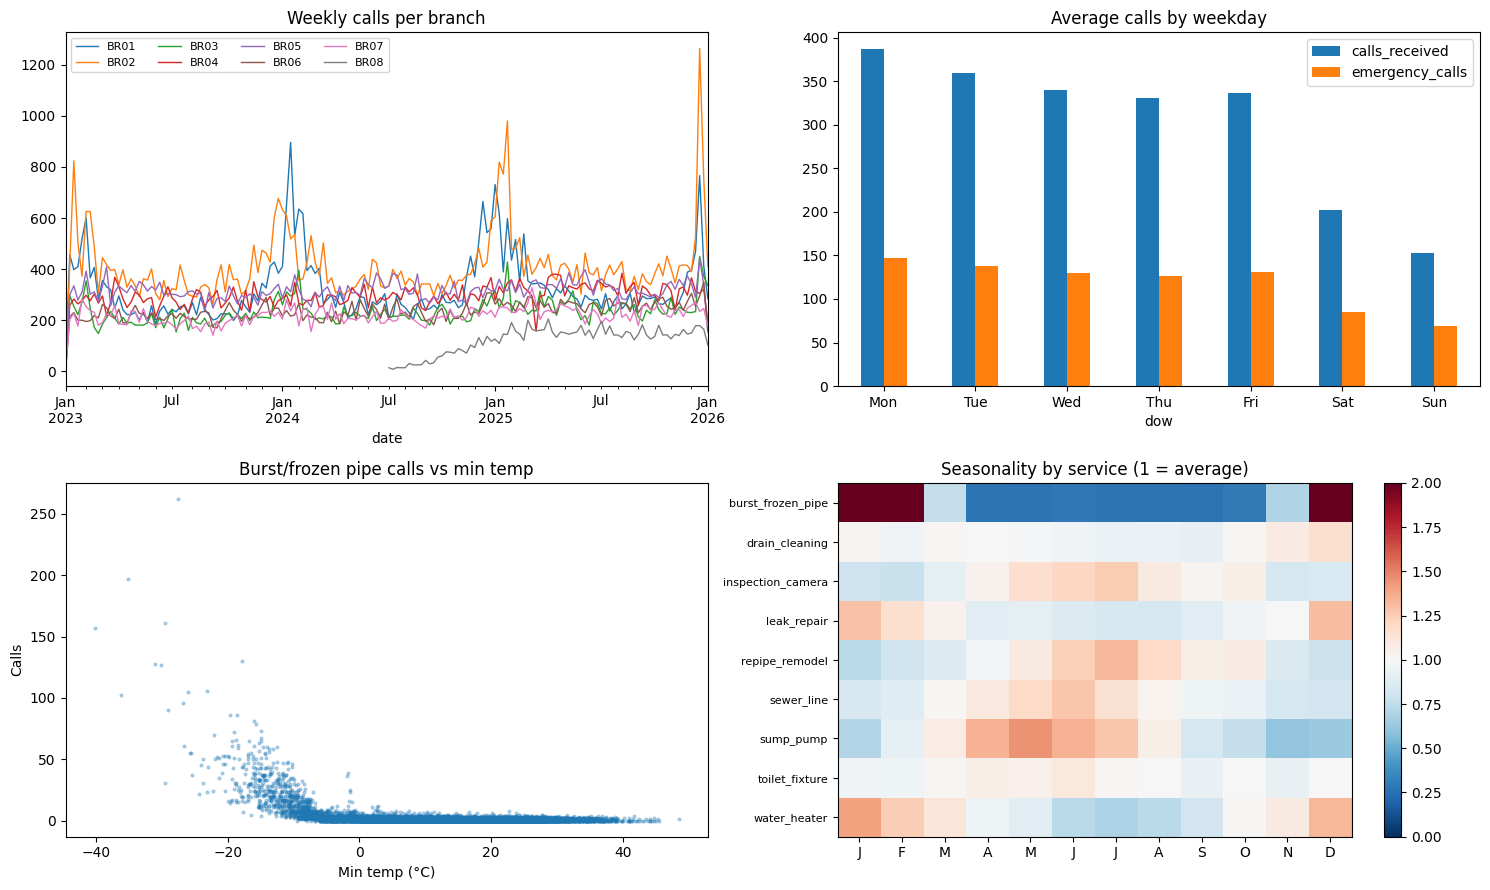

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
wk = df.groupby(["branch_id", pd.Grouper(key="date", freq="W")]).calls_received.sum().unstack(0)
wk.plot(ax=ax[0, 0], lw=1)
ax[0, 0].set_title("Weekly calls per branch"); ax[0, 0].legend(ncol=4, fontsize=8)
d = df.assign(dow=df.date.dt.dayofweek)
d.groupby("dow")[["calls_received", "emergency_calls"]].sum().div(d.date.nunique() / 7) \
 .plot.bar(ax=ax[0, 1])
ax[0, 1].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
ax[0, 1].set_title("Average calls by weekday")
bp = df[df.service_type == "burst_frozen_pipe"]
ax[1, 0].scatter(bp.temp_min_c, bp.calls_received, s=4, alpha=0.3)
ax[1, 0].set(title="Burst/frozen pipe calls vs min temp", xlabel="Min temp (°C)", ylabel="Calls")
m = df.groupby(["service_type", df.date.dt.month]).calls_received.mean().unstack()
m = m.div(m.mean(axis=1), axis=0)
im = ax[1, 1].imshow(m, cmap="RdBu_r", vmin=0, vmax=2, aspect="auto")
ax[1, 1].set_yticks(range(len(m)), m.index, fontsize=8)
ax[1, 1].set_xticks(range(12), list("JFMAMJJASOND"))
ax[1, 1].set_title("Seasonality by service (1 = average)"); plt.colorbar(im, ax=ax[1, 1])
plt.tight_layout(); plt.show()

In [6]:
import numpy as np
SPLIT = pd.Timestamp("2025-07-01")
train = df[(df.date < SPLIT) & df.calls_received.notna()]
test  = df[(df.date >= SPLIT) & df.calls_received.notna()]
print(len(train), len(test))

60714 13248


In [7]:
g = df.groupby(["branch_id", "service_type"])["calls_filled"]
for L in (28, 35, 42, 49):
    df[f"lag_{L}"] = g.shift(L)
df["baseline"] = df[["lag_28", "lag_35", "lag_42", "lag_49"]].mean(axis=1)
def wape(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return 100 * np.abs(y - p).sum() / y.sum()
test = df[(df.date >= SPLIT) & df.calls_received.notna()]
print("branch × service × day WAPE:", round(wape(test.calls_received, test.baseline), 1))
bd = test.groupby(["date", "branch_id"])[["calls_received", "baseline"]].sum()
print("branch × day WAPE:", round(wape(bd.calls_received, bd.baseline), 1))

branch × service × day WAPE: 56.2
branch × day WAPE: 24.9


In [8]:
keys = ["branch_id", "service_type"]
g = df.groupby(keys)["calls_filled"]
df["lag_364"] = g.shift(364)
s28 = g.shift(28)
grp = [df.branch_id, df.service_type]
df["roll_mean_7"]  = s28.groupby(grp).transform(lambda s: s.rolling(7,  min_periods=3).mean())
df["roll_mean_28"] = s28.groupby(grp).transform(lambda s: s.rolling(28, min_periods=7).mean())
df["roll_std_28"]  = s28.groupby(grp).transform(lambda s: s.rolling(28, min_periods=7).std())
df["dow"] = df.date.dt.dayofweek
doy = df.date.dt.dayofyear
df["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
df["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
df["days_since_open"] = (df.date - df.open_date).dt.days
wg = df.groupby(keys)
df["freeze_severity"] = np.clip(-6 - df.temp_min_c, 0, None)
df["temp_min_lag1"]   = wg.temp_min_c.shift(1)
df["thaw_day"]        = ((df.temp_min_lag1 <= -8) & (df.temp_min_c > -2)).astype(int)
df["rain_3d"]         = wg.precip_mm.transform(lambda s: s.rolling(3, min_periods=1).sum())
def adstock(x, decay=0.55):
    out, prev = np.zeros(len(x)), 0.0
    for i, v in enumerate(x):
        prev = v + decay * prev
        out[i] = prev
    return out
df["mkt_adstock"] = wg.marketing_spend_usd.transform(lambda s: adstock(s.values))
for c in ["branch_id", "service_type", "climate_zone"]:
    df[c] = df[c].astype("category")
FEATURES = [
    "branch_id", "service_type", "climate_zone", "households_k", "avg_housing_age_yrs", "days_since_open",
    "dow", "month", "doy_sin", "doy_cos", "is_holiday", "is_brown_friday", "is_christmas_week", "is_school_holiday",
    "temp_min_c", "temp_avg_c", "precip_mm", "snow_cm", "freeze_severity", "thaw_day", "rain_3d",
    "marketing_spend_usd", "promo_active", "mkt_adstock",
    "lag_28", "lag_35", "lag_42", "lag_364", "baseline", "roll_mean_7", "roll_mean_28", "roll_std_28",
]
train = df[(df.date < SPLIT) & df.calls_received.notna() & df.lag_49.notna()]
test  = df[(df.date >= SPLIT) & df.calls_received.notna()].copy()

In [9]:
import lightgbm as lgb
model = lgb.LGBMRegressor(
    objective="tweedie", tweedie_variance_power=1.2, 
    n_estimators=800, learning_rate=0.04, num_leaves=63, min_child_samples=40,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
    random_state=7, verbose=-1,
)
model.fit(train[FEATURES], train.calls_received)
test["pred"] = model.predict(test[FEATURES])
print("branch × service × day WAPE:", round(wape(test.calls_received, test.pred), 1),
      "| baseline", round(wape(test.calls_received, test.baseline), 1))
bd = test.groupby(["date", "branch_id"], observed=True)[["calls_received", "pred", "baseline"]].sum()
print("branch × day WAPE:", round(wape(bd.calls_received, bd.pred), 1),
      "| baseline", round(wape(bd.calls_received, bd.baseline), 1))
imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES)
print((100 * imp / imp.sum()).sort_values(ascending=False).head(10).round(1))

branch × service × day WAPE: 48.7 | baseline 56.2
branch × day WAPE: 19.9 | baseline 24.9
baseline           43.2
roll_mean_28       14.7
service_type        6.5
dow                 4.4
roll_mean_7         4.4
freeze_severity     2.4
lag_364             2.2
roll_std_28         2.1
temp_avg_c          2.1
doy_cos             1.9
dtype: float64


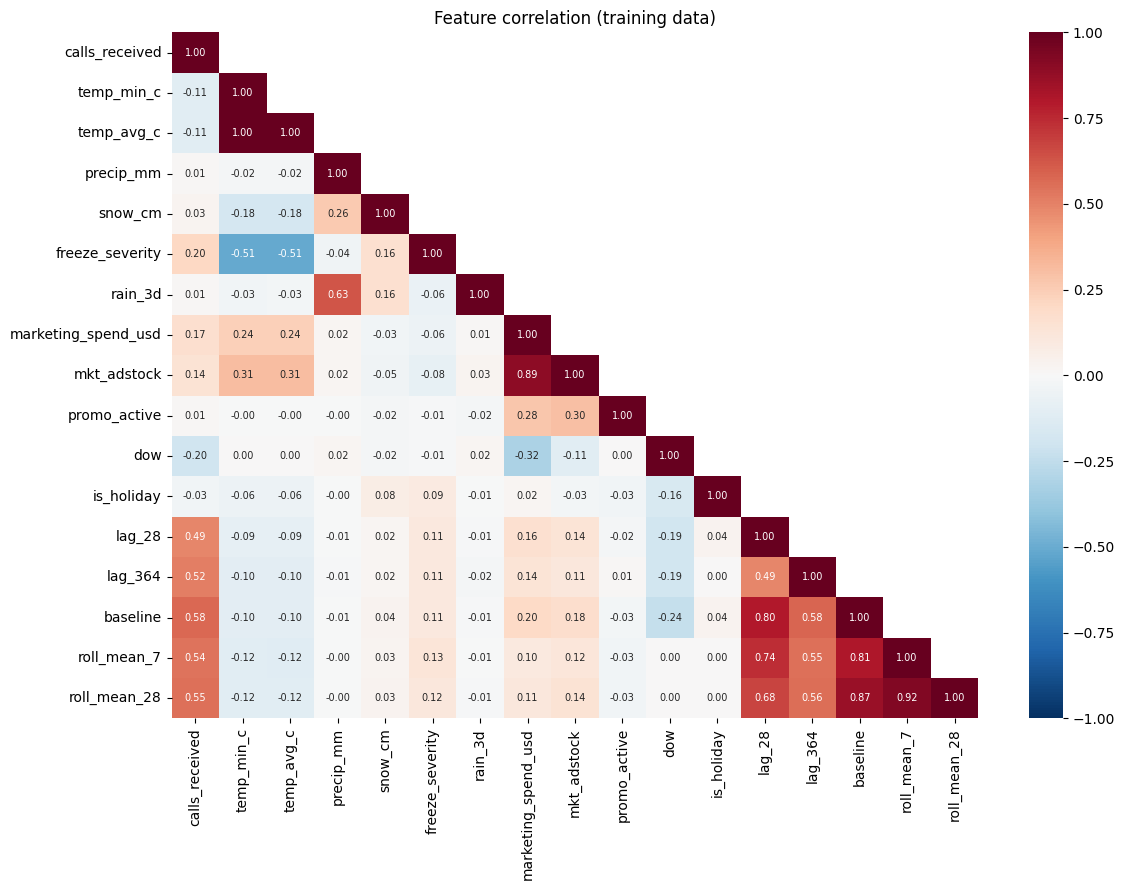

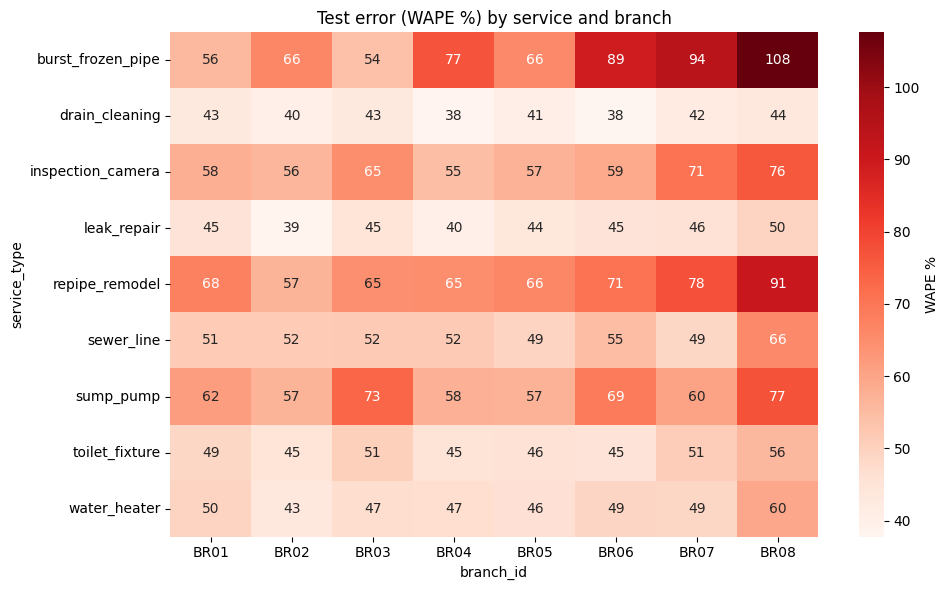

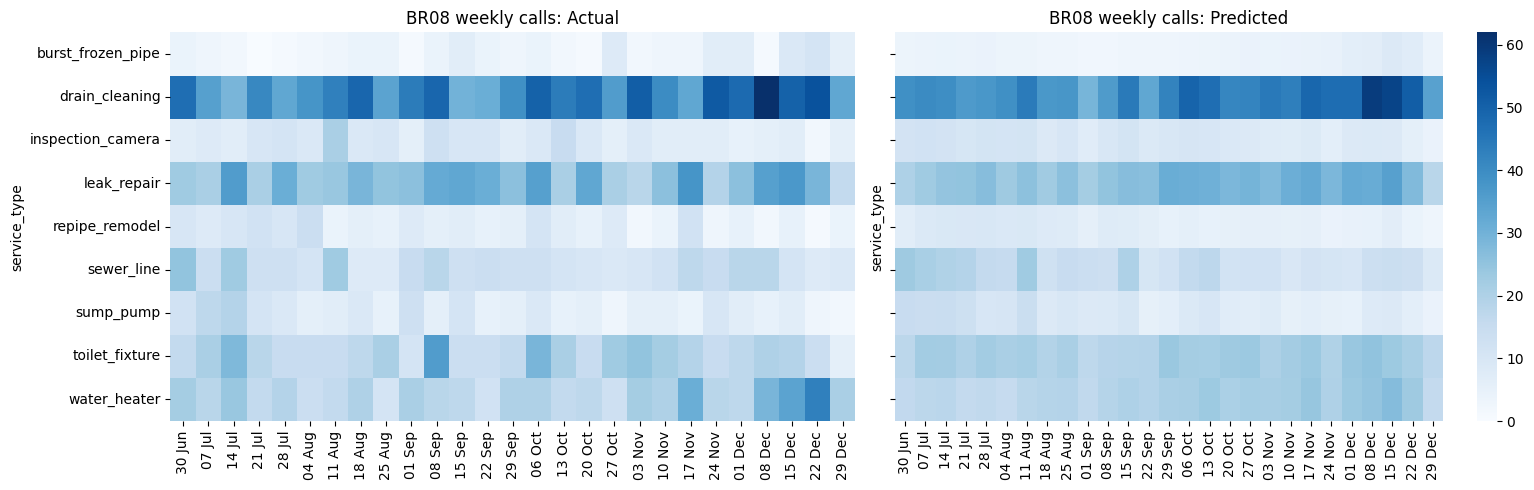

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
num = ["calls_received", "temp_min_c", "temp_avg_c", "precip_mm", "snow_cm", "freeze_severity", "rain_3d",
       "marketing_spend_usd", "mkt_adstock", "promo_active", "dow", "is_holiday",
       "lag_28", "lag_364", "baseline", "roll_mean_7", "roll_mean_28"]
corr = train[num].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1))
plt.title("Feature correlation (training data)")
plt.tight_layout(); plt.show()
err = (test.groupby(["service_type", "branch_id"], observed=True)
           .apply(lambda g: wape(g.calls_received, g.pred), include_groups=False)
           .unstack())
plt.figure(figsize=(10, 6))
sns.heatmap(err, cmap="Reds", annot=True, fmt=".0f", cbar_kws={"label": "WAPE %"})
plt.title("Test error (WAPE %) by service and branch")
plt.tight_layout(); plt.show()
B = "BR08"
t = test[test.branch_id == B].assign(week=lambda d: d.date.dt.to_period("W").dt.start_time)
wk = t.groupby(["service_type", "week"], observed=True)[["calls_received", "pred"]].sum()
fig, ax = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
vmax = wk.max().max()
for a, col, title in zip(ax, ["calls_received", "pred"], ["Actual", "Predicted"]):
    m = wk[col].unstack()
    m.columns = m.columns.strftime("%d %b")
    sns.heatmap(m, ax=a, cmap="Blues", vmin=0, vmax=vmax, cbar=a is ax[1])
    a.set_title(f"{B} weekly calls: {title}"); a.set_xlabel("")
plt.tight_layout(); plt.show()

In [11]:
params = dict(objective="tweedie", tweedie_variance_power=1.2, n_estimators=800, learning_rate=0.04,
              num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=1.0, random_state=7, verbose=-1)
GROUPS = {
    "Weather":   ["temp_min_c", "temp_avg_c", "precip_mm", "snow_cm", "freeze_severity", "thaw_day", "rain_3d"],
    "Marketing": ["marketing_spend_usd", "promo_active", "mkt_adstock"],
    "Calendar":  ["dow", "month", "doy_sin", "doy_cos", "is_holiday", "is_brown_friday",
                  "is_christmas_week", "is_school_holiday"],
    "History":   ["lag_28", "lag_35", "lag_42", "lag_364", "baseline", "roll_mean_7", "roll_mean_28", "roll_std_28"],
}
def branch_day_wape(feats):
    m = lgb.LGBMRegressor(**params).fit(train[feats], train.calls_received)
    p = test.assign(p=m.predict(test[feats])).groupby(["date", "branch_id"], observed=True)[["calls_received", "p"]].sum()
    return wape(p.calls_received, p.p)
full = branch_day_wape(FEATURES)
rows = [("All features", full)]
for name, cols in GROUPS.items():
    rows.append((f"Without {name}", branch_day_wape([f for f in FEATURES if f not in cols])))
abl = pd.DataFrame(rows, columns=["Model", "WAPE %"])
abl["Change vs full"] = abl["WAPE %"] - full
print(abl.round(2).to_string(index=False))

            Model  WAPE %  Change vs full
     All features   19.93            0.00
  Without Weather   21.28            1.35
Without Marketing   20.10            0.17
 Without Calendar   24.11            4.18
  Without History   19.56           -0.37


P10–P90 coverage: 73.1% (target 80%)


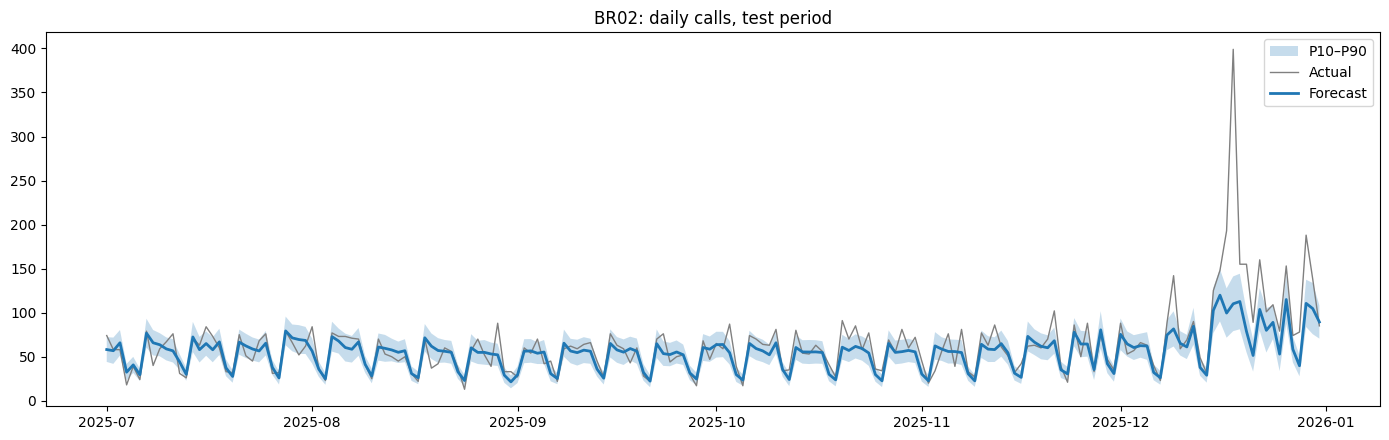

In [12]:
q = {}
for a in (0.1, 0.9):
    qp = {k: v for k, v in params.items() if k != "tweedie_variance_power"}
    qp.update(objective="quantile", alpha=a)
    q[a] = lgb.LGBMRegressor(**qp).fit(train[FEATURES], train.calls_received)
test["p10"] = np.minimum(np.clip(q[0.1].predict(test[FEATURES]), 0, None), test.pred)
test["p90"] = np.maximum(q[0.9].predict(test[FEATURES]), test.pred)
inside = (test.calls_received >= test.p10) & (test.calls_received <= test.p90)
print(f"P10–P90 coverage: {inside.mean():.1%} (target 80%)")
Z = 1.2816
B = "BR02"
v = test[test.branch_id == B].assign(var=lambda d: ((d.p90 - d.p10) / (2 * Z)) ** 2)
v = v.groupby("date")[["calls_received", "pred", "var"]].sum()
sd = np.sqrt(v["var"])
plt.figure(figsize=(14, 4.5))
plt.fill_between(v.index, np.clip(v.pred - Z * sd, 0, None), v.pred + Z * sd, alpha=0.25, label="P10–P90")
plt.plot(v.index, v.calls_received, color="gray", lw=1, label="Actual")
plt.plot(v.index, v.pred, lw=2, label="Forecast")
plt.title(f"{B}: daily calls, test period"); plt.legend(); plt.tight_layout(); plt.show()

In [13]:
cold_svc = {"burst_frozen_pipe": 1.0, "leak_repair": 0.15, "water_heater": 0.05}
w = df.service_type.astype(str).map(cold_svc).fillna(0)
df["svc_freeze"] = df.freeze_severity * w
df["svc_thaw"]   = df.thaw_day * w
F2 = FEATURES + ["svc_freeze", "svc_thaw"]
train = df[(df.date < SPLIT) & df.calls_received.notna() & df.lag_49.notna()]
test  = df[(df.date >= SPLIT) & df.calls_received.notna()].copy()
PP = {**params, "objective": "poisson"}
PP.pop("tweedie_variance_power", None)
main = lgb.LGBMRegressor(**PP).fit(train[F2], train.calls_received)
test["pred"] = main.predict(test[F2])
mb = train.service_type == "burst_frozen_pipe"
tb = test.service_type == "burst_frozen_pipe"
burst = lgb.LGBMRegressor(**PP).fit(train.loc[mb, F2], train.loc[mb, "calls_received"])
test.loc[tb, "pred"] = burst.predict(test.loc[tb, F2])
bd  = test.groupby(["date", "branch_id"], observed=True)[["calls_received", "pred"]].sum()
dec = bd.loc[pd.IndexSlice["2025-12-01":, :], :]
print("branch × day WAPE:", round(wape(bd.calls_received, bd.pred), 2))
print("December WAPE:", round(wape(dec.calls_received, dec.pred), 1),
      "| December bias:", f"{100 * (dec.pred.sum() / dec.calls_received.sum() - 1):+.1f}%")

branch × day WAPE: 18.88
December WAPE: 19.9 | December bias: -6.0%


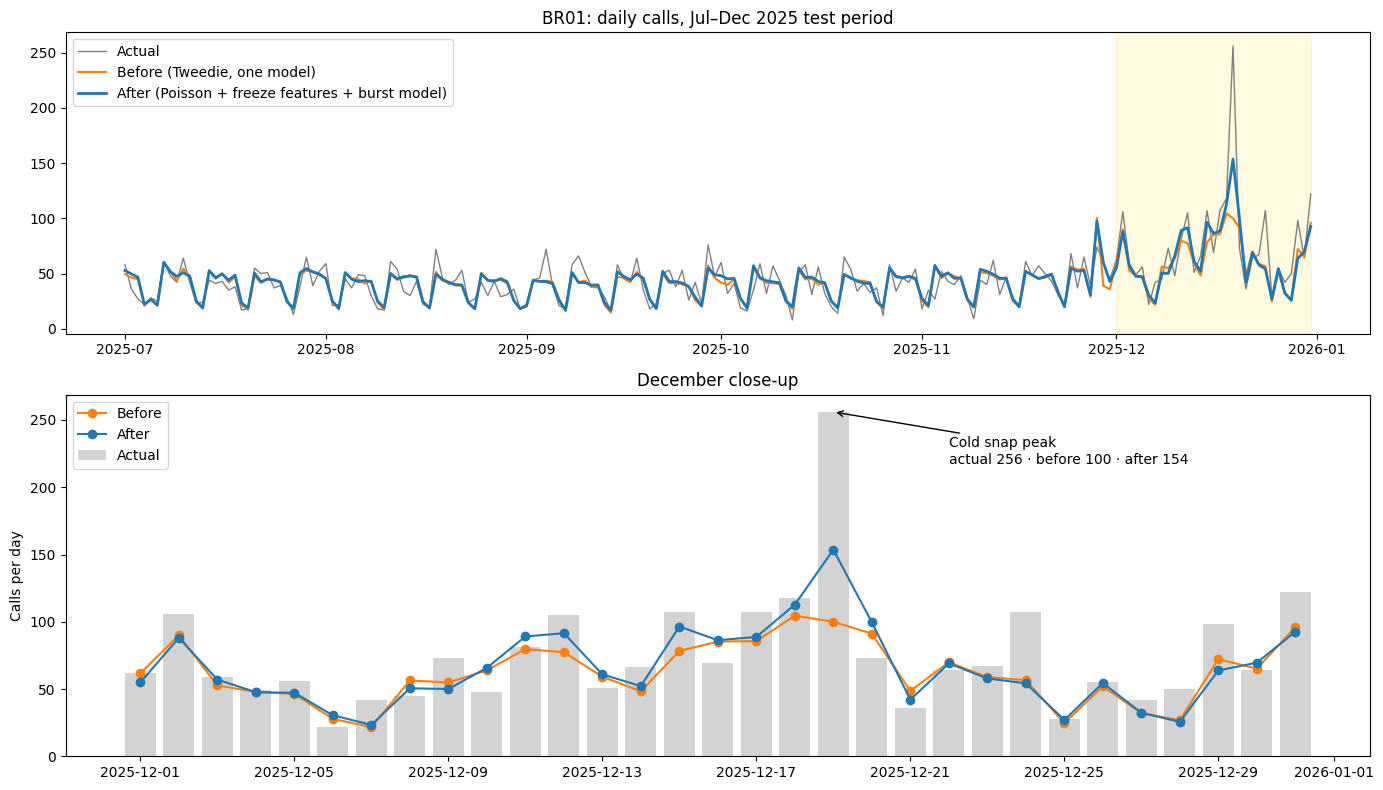

In [14]:
import matplotlib.pyplot as plt
test["pred_old"] = model.predict(test[FEATURES])  
B = "BR01"
d = test[test.branch_id == B].groupby("date")[["calls_received", "pred_old", "pred"]].sum()
fig, ax = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={"height_ratios": [1, 1.2]})
ax[0].plot(d.index, d.calls_received, color="gray", lw=1, label="Actual")
ax[0].plot(d.index, d.pred_old, color="tab:orange", lw=1.5, label="Before (Tweedie, one model)")
ax[0].plot(d.index, d.pred, color="tab:blue", lw=2, label="After (Poisson + freeze features + burst model)")
ax[0].axvspan(pd.Timestamp("2025-12-01"), d.index.max(), color="gold", alpha=0.12)
ax[0].set_title(f"{B}: daily calls, Jul–Dec 2025 test period"); ax[0].legend(loc="upper left")
z = d.loc["2025-12-01":]
ax[1].bar(z.index, z.calls_received, color="lightgray", label="Actual")
ax[1].plot(z.index, z.pred_old, "o-", color="tab:orange", label="Before")
ax[1].plot(z.index, z.pred, "o-", color="tab:blue", label="After")
pk = z.calls_received.idxmax()
ax[1].annotate(f"Cold snap peak\nactual {z.calls_received[pk]:.0f} · before {z.pred_old[pk]:.0f} · after {z.pred[pk]:.0f}",
               xy=(pk, z.calls_received[pk]), xytext=(pk + pd.Timedelta(days=3), z.calls_received[pk] * 0.85),
               arrowprops=dict(arrowstyle="->"))
ax[1].set_title("December close-up"); ax[1].legend(loc="upper left"); ax[1].set_ylabel("Calls per day")
plt.tight_layout(); plt.show()

In [15]:
import json, os
OUT = "/kaggle/working/models"
os.makedirs(OUT, exist_ok=True)
def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"WAPE_%": round(wape(y, p), 2), "MAE": round(float(np.mean(np.abs(y - p))), 3),
            "RMSE": round(float(np.sqrt(np.mean((y - p) ** 2))), 3),
            "Bias_%": round(100 * (p.sum() - y.sum()) / y.sum(), 2)}
QP = {k: v for k, v in PP.items() if k != "objective"}
BURST = "burst_frozen_pipe"
q10 = lgb.LGBMRegressor(**QP, objective="quantile", alpha=0.1).fit(train[F2], train.calls_received)
q90 = lgb.LGBMRegressor(**QP, objective="quantile", alpha=0.9).fit(train[F2], train.calls_received)
test["p10"] = np.minimum(np.clip(q10.predict(test[F2]), 0, None), test.pred)
test["p90"] = np.maximum(q90.predict(test[F2]), test.pred)
bd = test.groupby(["date", "branch_id"], observed=True)[["calls_received", "pred", "baseline"]].sum()
inside = (test.calls_received >= test.p10) & (test.calls_received <= test.p90)
imp = pd.Series(main.booster_.feature_importance("gain"), index=F2)
full = df[df.calls_received.notna() & df.lag_49.notna()]
fb = full.service_type == BURST
models = {
    "model":       lgb.LGBMRegressor(**PP).fit(full[F2], full.calls_received),
    "model_burst": lgb.LGBMRegressor(**PP).fit(full.loc[fb, F2], full.loc[fb, "calls_received"]),
    "model_p10":   lgb.LGBMRegressor(**QP, objective="quantile", alpha=0.1).fit(full[F2], full.calls_received),
    "model_p90":   lgb.LGBMRegressor(**QP, objective="quantile", alpha=0.9).fit(full[F2], full.calls_received),
}
for name, m in models.items():
    m.booster_.save_model(f"{OUT}/{name}.txt")
ss = jobs.groupby("service_type").agg(avg_duration_h=("duration_hours", "mean"),
                                      avg_invoice_usd=("invoice_usd", "mean")).round(2)
meta = {
    "features": F2,
    "cat_features": ["branch_id", "service_type", "climate_zone"],
    "categories": {c: [str(x) for x in df[c].cat.categories] for c in ["branch_id", "service_type", "climate_zone"]},
    "burst_service": BURST,
    "metrics": {"LightGBM (this model)": metrics(test.calls_received, test.pred),
                "Naive: avg of last 4 same weekdays": metrics(test.calls_received, test.baseline)},
    "metrics_branch_day": {"LightGBM (this model)": metrics(bd.calls_received, bd.pred),
                           "Naive: avg of last 4 same weekdays": metrics(bd.calls_received, bd.baseline)},
    "wape_by_branch": {str(b): round(wape(g.calls_received, g.pred), 2) for b, g in bd.groupby(level="branch_id", observed=True)},
    "wape_by_service": {str(s): round(wape(g.calls_received, g.pred), 2) for s, g in test.groupby("service_type", observed=True)},
    "interval_coverage": float(inside.mean()),
    "best_iteration": int(PP["n_estimators"]),
    "feature_importance": {k: round(float(v), 2) for k, v in (100 * imp / imp.sum()).sort_values(ascending=False).items()},
    "service_stats": {s: {"avg_duration_h": float(r.avg_duration_h), "avg_invoice_usd": float(r.avg_invoice_usd)}
                      for s, r in ss.iterrows()},
    "val_start": str(SPLIT.date()),
    "history_end": str(df.date.max().date()),
}
with open(f"{OUT}/meta.json", "w") as f:
    json.dump(meta, f, indent=2)
v = test[["date", "branch_id", "service_type", "calls_received", "pred", "p10", "p90", "baseline"]] \
        .rename(columns={"baseline": "dow_mean_4w"}).copy()
v["date"] = v.date.dt.strftime("%Y-%m-%d")
for c in ["branch_id", "service_type"]:
    v[c] = v[c].astype(str)
v.round(4).to_csv(f"{OUT}/validation.csv", index=False)
print("branch × day WAPE:", meta["metrics_branch_day"]["LightGBM (this model)"]["WAPE_%"],
      "| P10–P90 coverage:", f"{inside.mean():.1%}")
print(sorted(os.listdir(OUT)))

branch × day WAPE: 18.88 | P10–P90 coverage: 73.3%
['meta.json', 'model.txt', 'model_burst.txt', 'model_p10.txt', 'model_p90.txt', 'validation.csv']
